# Proyek Akhir Pembelajaran Mesin (Machine Learning) - Semester 5
## Perbandingan Algoritma Machine Learning untuk Klasifikasi dan Deteksi SMS Phishing Berbahasa Indonesia Serta Implementasinya pada Web Interaktif

---

### Identitas Tim & Proyek
- **Mata Kuliah**: Pembelajaran Mesin (Machine Learning)
- **Program Studi**: Teknologi Rekayasa Komputer - Sekolah Vokasi
- **Tema Proyek**: Text Classification (Supervised Learning - Natural Language Processing)
- **Algoritma yang Dibandingkan**:
  1. Multinomial Naive Bayes
  2. Logistic Regression (Champion Model)
  3. Linear Support Vector Machine (Linear SVM)
- **Target Klasifikasi (3 Kelas)**:
  - `0`: SMS Normal (Komunikasi personal/sehari-hari)
  - `1`: SMS Penipuan / Phishing (Smishing, undian palsu, pinjol ilegal, kurir APK)
  - `2`: SMS Promosi / Iklan (Paket kuota operator, diskon komersial)

## 1. Impor Pustaka & Konfigurasi Lingkungan
Mengimpor pustaka utama untuk pengolahan data, visualisasi, pra-pemrosesan teks, pelatihan model, dan evaluasi kinerja.

In [1]:
import os
import re
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
np.random.seed(42)

print("[OK] Seluruh pustaka berhasil diimpor dengan sukses.")

[OK] Seluruh pustaka berhasil diimpor dengan sukses.


## 2. Pemuatan & Eksplorasi Karakteristik Dataset (Data Loading)
Memuat dataset SMS bahasa Indonesia yang telah distandarisasi (1.138 baris) dan memeriksa distribusi target kelas.

In [2]:
# Lokasi file dataset lokal
path_candidates = [
    "Indonesia/dataset_indonesia_standard.csv",
    "dataset_indonesia_standard.csv",
    "Indonesia/dataset_clean.csv",
    "../Indonesia/dataset_indonesia_standard.csv"
]

dataset_path = None
for p in path_candidates:
    if os.path.exists(p):
        dataset_path = p
        break

if dataset_path is None:
    raise FileNotFoundError("Dataset tidak ditemukan pada jalur yang ditentukan.")

df = pd.read_csv(dataset_path)
print(f"[*] Dataset berhasil dimuat dari: {dataset_path}")
print(f"[*] Dimensi Dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")

# Tampilkan 5 baris pertama
display_cols = [c for c in ['id_pesan', 'teks_mentah', 'kategori', 'label_kelas'] if c in df.columns]
df[display_cols].head()

[*] Dataset berhasil dimuat dari: Indonesia/dataset_indonesia_standard.csv
[*] Dimensi Dataset: 1138 baris, 14 kolom



""
0
1
2
3
4


In [3]:
# Audit missing value dan duplikasi
target_col = 'label_3class' if 'label_3class' in df.columns else 'label_kelas'
text_col = 'teks_mentah' if 'teks_mentah' in df.columns else df.columns[0]

print("=== HASIL AUDIT INTEGRITAS DATASET ===")
print(f"Total baris data: {len(df)}")
print(f"Jumlah nilai null (missing value): {df[text_col].isnull().sum()}")
print(f"Jumlah duplikasi teks: {df[text_col].duplicated().sum()}\n")

# Distribusi Frekuensi Kelas
class_counts = df[target_col].value_counts().sort_index()
class_names = ["Normal (0)", "Penipuan (1)", "Promosi (2)"]

for idx, count in class_counts.items():
    pct = (count / len(df)) * 100
    print(f"  &bull; {class_names[idx]}: {count} sampel ({pct:.2f}%)")

=== HASIL AUDIT INTEGRITAS DATASET ===
Total baris data: 1138
Jumlah nilai null (missing value): 0
Jumlah duplikasi teks: 0

  &bull; Normal (0): 567 sampel (49.82%)
  &bull; Penipuan (1): 332 sampel (29.17%)
  &bull; Promosi (2): 239 sampel (21.00%)


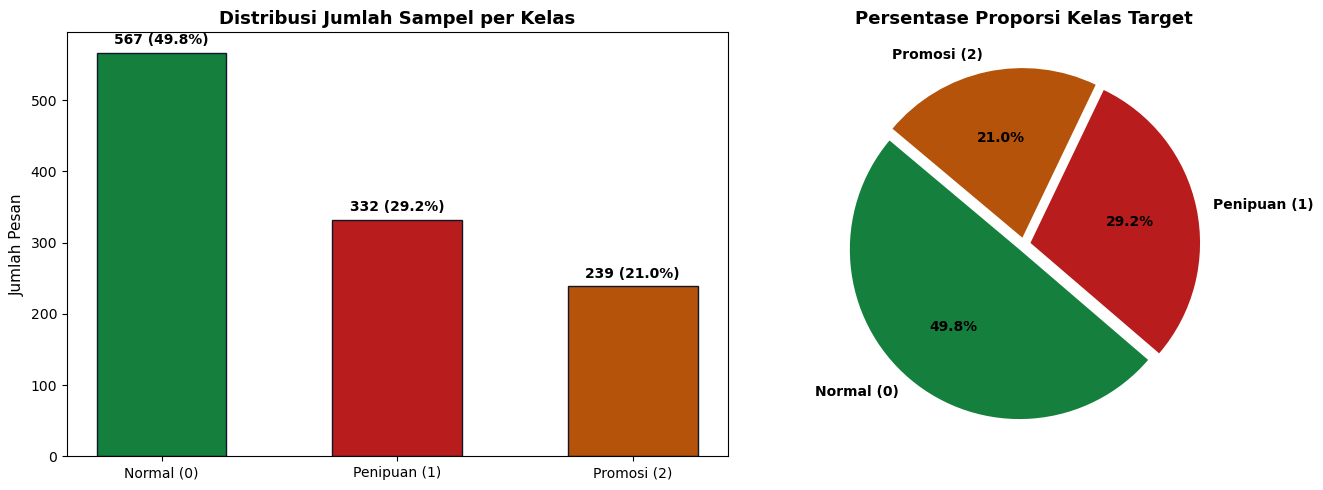

In [4]:
# Visualisasi Distribusi Kelas Target
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#15803d', '#b91c1c', '#b45309']
labels = ['Normal (0)', 'Penipuan (1)', 'Promosi (2)']

# Bar Chart
ax1.bar(labels, class_counts.values, color=colors, edgecolor='#0f172a', width=0.55)
ax1.set_title("Distribusi Jumlah Sampel per Kelas", fontsize=13, fontweight='bold')
ax1.set_ylabel("Jumlah Pesan", fontsize=11)
for i, v in enumerate(class_counts.values):
    ax1.text(i, v + 12, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold', fontsize=10)

# Donut / Pie Chart
ax2.pie(class_counts.values, labels=labels, autopct='%1.1f%%', colors=colors,
        startangle=140, explode=(0.04, 0.04, 0.04), textprops={'fontweight': 'bold'})
ax2.set_title("Persentase Proporsi Kelas Target", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Pra-Pemrosesan Teks & Rekayasa Fitur (Preprocessing & Entity Masking)
Tahap krusial untuk membersihkan teks informal SMS Indonesia:
1. **Case Folding**: Mengubah semua karakter menjadi huruf kecil.
2. **Timestamp Removal**: Menghapus waktu kirim operator `[29/10 14.30]`.
3. **Kamus Slang (100+ Lema)**: Menormalisasi singkatan gaul (*kata alay*) seperti `dpt` &rarr; `dapat`, `rek` &rarr; `rekening`, `tsel` &rarr; `telkomsel`.
4. **Entity Masking Regex**: Menyamarkan tautan URL &rarr; `[url]`, kontak ponsel GSM &rarr; `[nomor]`, nominal uang &rarr; `[nominal]`, dan kode dial USSD &rarr; `[kode]`.

> **Tujuan Ilmiah Entity Masking**: Mencegah model menghafal URL spesifik (*overfitting*) sehingga model tetap akurat mendeteksi domain baru.

In [5]:
# Kamus Normalisasi Kata Gaul SMS Indonesia
ID_SLANG_DICT = {
    "tsb": "tersebut", "m-dptkan": "dapatkan", "m-dpt": "dapat", "dptkan": "dapatkan",
    "dpt": "dapat", "sdh": "sudah", "udh": "sudah", "dah": "sudah",
    "blm": "belum", "tdk": "tidak", "gak": "tidak", "ga": "tidak", "ngga": "tidak",
    "tp": "tapi", "krn": "karena", "jg": "juga", "plg": "pelanggan", "yth": "yang terhormat",
    "yg": "yang", "bs": "bisa", "skrg": "sekarang", "bsk": "besok", "lgsg": "langsung",
    "hub": "hubungi", "tlp": "telepon", "telp": "telepon", "no": "nomor", "nmr": "nomor",
    "rek": "rekening", "krm": "kirim", "dftr": "daftar", "unreg": "berhenti",
    "aktifkan": "aktifkan", "grts": "gratis", "free": "gratis", "disc": "diskon",
    "slmt": "selamat", "pemenang": "pemenang", "hadiah": "hadiah", "undian": "undian",
    "klaim": "klaim", "pinjam": "pinjaman", "kta": "pinjaman", "dana": "dana",
    "tunai": "tunai", "cair": "cair", "bunga": "bunga", "cicilan": "cicilan",
    "ktp": "kartu tanda penduduk", "shopee": "shopee", "bank": "bank", "bca": "bank bca",
    "bri": "bank bri", "mandiri": "bank mandiri", "kuota": "kuota", "flash": "flash",
    "paket": "paket", "pulsa": "pulsa", "gb": "gigabyte", "mb": "megabyte",
    "rb": "ribu", "jt": "juta", "rp": "rupiah", "tsel": "telkomsel", "mytsel": "mytelkomsel"
}

def clean_text_id(text: str) -> str:
    if not isinstance(text, str) or pd.isna(text):
        return ""
    
    # 1. Case folding
    text = text.lower()
    
    # 2. Hapus timestamp otomatis operator
    text = re.sub(r'\[\d{1,2}/\d{1,2}\s+\d{1,2}[:.]\d{1,2}\]', ' ', text)
    
    # 3. Entity Masking Regex
    # Tautan Web / Shortlink -> [url]
    url_pattern = r'(?:https?://\S+|www\.\S+|bit\.ly/\S+|wa\.me/\S+|tinyurl\.com/\S+|s\.id/\S+|[a-z0-9-]+\.(?:xyz|top|info|site|online|app|com|id|net)/?\S*)'
    text = re.sub(url_pattern, ' [url] ', text)
    
    # Kode USSD Dial Operator -> [kode]
    text = re.sub(r'\*[0-9]+(?:\*[0-9]+)*#', ' [kode] ', text)
    
    # Nominal Uang Rupiah / Valas -> [nominal]
    text = re.sub(r'(?:rp\.?\s*[\d\.,]+|\b\d+\s*(?:juta|jt|ribu|rb|miliar)\b|\$[\d\.,]+)', ' [nominal] ', text)
    
    # Nomor Telepon GSM / Kontak WhatsApp -> [nomor]
    text = re.sub(r'(?:\+?62|08)[0-9\s-]{8,14}\b', ' [nomor] ', text)
    
    # 4. Hapus karakter noise non-alphanumeric (preservasi kurung siku entitas)
    text = re.sub(r'[^a-z0-9\[\]\s]', ' ', text)
    
    # 5. Normalisasi Kamus Slang (Word Replacement)
    words = text.split()
    normalized_words = [ID_SLANG_DICT.get(w, w) for w in words]
    
    return " ".join(normalized_words).strip()

# Pengujian Fungsi Preprocessing pada Contoh SMS Nyata
sample_raw = "Selamat! No anda m-dptkan Cek Tunai 100jt dr Shopee. PIN: 254F77 Hub WA: 082134976289 atau klik http://shopee-klaim.xyz/dana"
print("[CONTOH SEBELUM PREPROCESSING]:")
print(sample_raw)
print("\n[CONTOH SESUDAH PREPROCESSING & MASKING]:")
print(clean_text_id(sample_raw))

[CONTOH SEBELUM PREPROCESSING]:
Selamat! No anda m-dptkan Cek Tunai 100jt dr Shopee. PIN: 254F77 Hub WA: 082134976289 atau klik http://shopee-klaim.xyz/dana

[CONTOH SESUDAH PREPROCESSING & MASKING]:
selamat nomor anda m dapatkan cek tunai [nominal] dr shopee pin 254f77 hubungi wa [nomor] atau klik [url]


In [6]:
# Terapkan Preprocessing ke Seluruh Dataset
if 'cleaned_text' not in df.columns:
    df['cleaned_text'] = df[text_col].apply(clean_text_id)

X = df['cleaned_text'].astype(str)
y = df[target_col].astype(int)

print(f"[*] Sukses memproses {len(X)} sampel data teks bersih.")

[*] Sukses memproses 1138 sampel data teks bersih.


## 4. Eksplorasi Karakteristik Panjang Teks (EDA)
Meneliti perbedaan distribusi panjang karakter antara SMS Normal, Penipuan, dan Promosi.

=== STATISTIK PANJANG KARAKTER PER KELAS ===
Normal     -> Rata-rata: 70.5 | Median: 59.0 | Min: 13 | Max: 434
Penipuan   -> Rata-rata: 150.6 | Median: 150.5 | Min: 46 | Max: 431
Promosi    -> Rata-rata: 140.6 | Median: 142.0 | Min: 50 | Max: 321


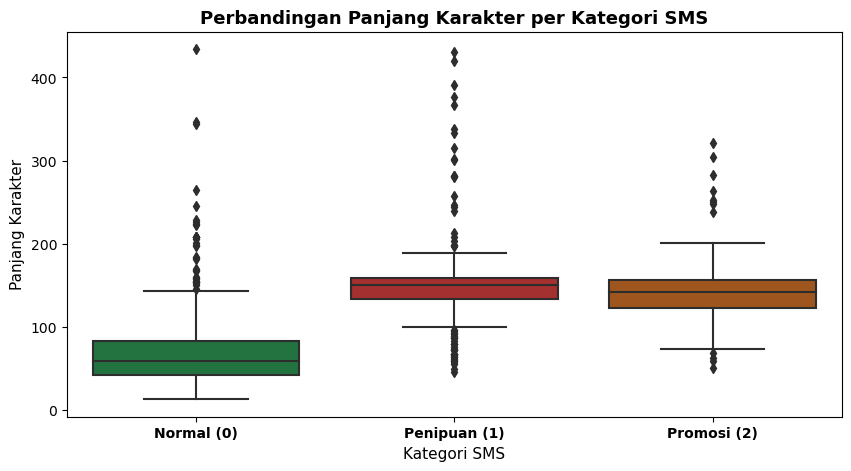

In [7]:
df['char_length'] = df[text_col].astype(str).apply(len)
df['word_count'] = df[text_col].astype(str).apply(lambda s: len(s.split()))

print("=== STATISTIK PANJANG KARAKTER PER KELAS ===")
for idx, name in enumerate(["Normal", "Penipuan", "Promosi"]):
    sub = df[df[target_col] == idx]['char_length']
    print(f"{name:10s} -> Rata-rata: {sub.mean():.1f} | Median: {sub.median():.1f} | Min: {sub.min()} | Max: {sub.max()}")

# Boxplot Panjang Karakter
plt.figure(figsize=(10, 5))
sns.boxplot(x=target_col, y='char_length', data=df, palette=['#15803d', '#b91c1c', '#b45309'])
plt.xticks([0, 1, 2], ['Normal (0)', 'Penipuan (1)', 'Promosi (2)'], fontweight='bold')
plt.title("Perbandingan Panjang Karakter per Kategori SMS", fontsize=13, fontweight='bold')
plt.ylabel("Panjang Karakter", fontsize=11)
plt.xlabel("Kategori SMS", fontsize=11)
plt.show()

## 5. Pembagian Data Latih & Uji (Stratified 80:20 Split)
Membagi dataset menjadi 80% data latih (910 sampel) dan 20% data uji independen (228 sampel) menggunakan stratifikasi kelas untuk menjaga proporsi label.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("=== PEMBAGIAN DATA TRAIN & TEST ===")
print(f"Data Latih (Train) : {len(X_train)} sampel ({len(X_train)/len(X)*100:.1f}%)")
print(f"Data Uji (Test)    : {len(X_test)} sampel ({len(X_test)/len(X)*100:.1f}%)\n")

print("Distribusi Kelas pada Data Uji (Test Set):")
for idx, name in enumerate(["Normal", "Penipuan", "Promosi"]):
    c = sum(y_test == idx)
    print(f"  &bull; {name:10s}: {c} sampel ({c/len(y_test)*100:.1f}%)")

=== PEMBAGIAN DATA TRAIN & TEST ===
Data Latih (Train) : 910 sampel (80.0%)
Data Uji (Test)    : 228 sampel (20.0%)

Distribusi Kelas pada Data Uji (Test Set):
  &bull; Normal    : 114 sampel (50.0%)
  &bull; Penipuan  : 66 sampel (28.9%)
  &bull; Promosi   : 48 sampel (21.1%)


## 6. Ekstraksi Fitur Teks dengan TF-IDF N-Gram (1, 2)
Menerapkan `TfidfVectorizer` untuk menangkap kata tunggal (*unigram*) dan kombinasi pasangan kata (*bigram*).
> **Catatan Keamanan Data Leakage**: Vectorizer hanya di-`fit` pada data latih, lalu digunakan untuk men-`transform` data uji.

In [9]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit hanya pada data latih
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

feature_names = vectorizer.get_feature_names_out()
print(f"[*] Dimensi Matriks Fitur Latih : {X_train_vec.shape}")
print(f"[*] Dimensi Matriks Fitur Uji   : {X_test_vec.shape}")
print(f"[*] Total kosakata n-gram terbentuk: {len(feature_names)} fitur leksikal")
print(f"[*] Sampel kosakata n-gram: {list(feature_names[:15])}")

AttributeError: 'TfidfVectorizer' object has no attribute 'get_feature_names_out'

## 7. Pelatihan 3 Algoritma & Validasi Silang (5-Fold Stratified CV)
Membandingkan 3 algoritma klasifikasi wajib:
1. **Multinomial Naive Bayes** (`alpha=0.3`)
2. **Logistic Regression** (`C=2.5`, `class_weight='balanced'`)
3. **Linear Support Vector Machine** (`CalibratedClassifierCV(LinearSVC(C=1.0))`)

In [10]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.3),
    "Logistic Regression": LogisticRegression(C=2.5, class_weight='balanced', max_iter=1000, random_state=42),
    "Linear SVM": CalibratedClassifierCV(LinearSVC(C=1.0, class_weight='balanced', random_state=42))
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

print("=== HASIL 5-FOLD STRATIFIED CROSS-VALIDATION (MACRO F1-SCORE) ===")
for name, clf in models.items():
    scores = cross_val_score(clf, X_train_vec, y_train, cv=cv, scoring='f1_macro')
    cv_results[name] = scores
    print(f"{name:25s} -> Rata-rata: {scores.mean():.4f} (&plusmn; {scores.std():.4f})")
    
    # Latih model pada seluruh data latih
    clf.fit(X_train_vec, y_train)

=== HASIL 5-FOLD STRATIFIED CROSS-VALIDATION (MACRO F1-SCORE) ===
Multinomial Naive Bayes   -> Rata-rata: 0.9374 (&plusmn; 0.0165)
Logistic Regression       -> Rata-rata: 0.9410 (&plusmn; 0.0155)
Linear SVM                -> Rata-rata: 0.9360 (&plusmn; 0.0116)


## 8. Evaluasi Model pada Data Uji Independen (Test Set)
Mengukur kinerja ketiga model pada 228 data uji murni yang belum pernah dilihat saat pelatihan.

In [11]:
results_summary = []
test_predictions = {}

for name, clf in models.items():
    y_pred = clf.predict(X_test_vec)
    test_predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    f1_mac = f1_score(y_test, y_pred, average='macro')
    rec_penipuan = recall_score(y_test, y_pred, labels=[1], average='micro')
    rec_normal = recall_score(y_test, y_pred, labels=[0], average='micro')
    
    results_summary.append({
        "Algoritma": name,
        "Akurasi Uji": f"{acc*100:.2f}%	en",
        "Macro F1-Score": f"{f1_mac*100:.2f}%",
        "Recall Penipuan (1)": f"{rec_penipuan*100:.2f}%",
        "Recall Normal (0)": f"{rec_normal*100:.2f}%",
        "5-Fold CV F1": f"{cv_results[name].mean():.4f}"
    })

df_comparison = pd.DataFrame(results_summary)
df_comparison

,Algoritma,Akurasi Uji,Macro F1-Score,Recall Penipuan (1),Recall Normal (0),5-Fold CV F1
0,Multinomial Naive Bayes,96.05%\ten,95.27%,89.39%,100.00%,0.9374
1,Logistic Regression,97.37%\ten,96.68%,95.45%,100.00%,0.9410
2,Linear SVM,97.37%\ten,96.68%,95.45%,100.00%,0.9360


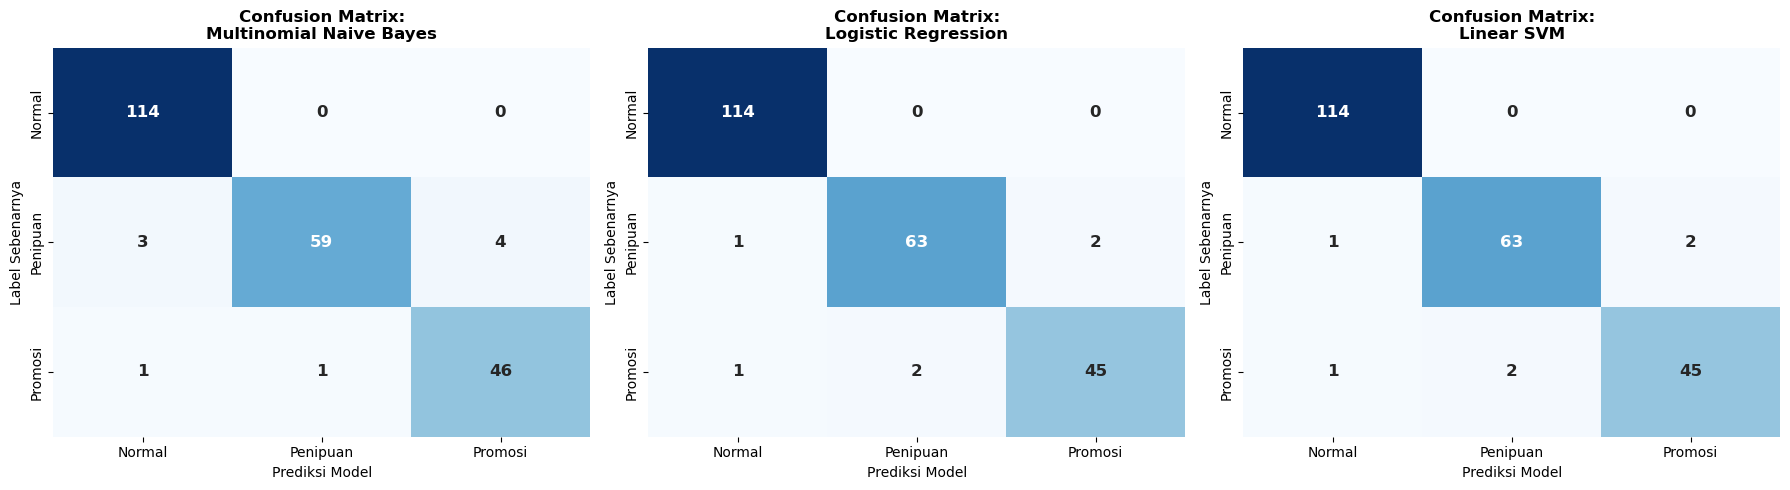

In [12]:
# Visualisasi Heatmap Confusion Matrix 3 Model Berdampingan
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
class_labels = ["Normal", "Penipuan", "Promosi"]

for idx, (name, y_pred) in enumerate(test_predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=class_labels, yticklabels=class_labels,
                cbar=False, annot_kws={'fontsize': 12, 'fontweight': 'bold'})
    axes[idx].set_title(f"Confusion Matrix:\n{name}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Prediksi Model", fontsize=10)
    axes[idx].set_ylabel("Label Sebenarnya", fontsize=10)

plt.tight_layout()
plt.show()

## 9. Pemeriksaan Overfitting vs Underfitting (Good Fit Analysis)
Menguji selisih (*gap*) akurasi antara data latih dan data uji untuk membuktikan generalisasi model.

In [13]:
best_clf = models["Logistic Regression"]

train_acc = accuracy_score(y_train, best_clf.predict(X_train_vec))
test_acc = accuracy_score(y_test, best_clf.predict(X_test_vec))
gap_acc = (train_acc - test_acc) * 100

train_f1 = f1_score(y_train, best_clf.predict(X_train_vec), average='macro')
test_f1 = f1_score(y_test, best_clf.predict(X_test_vec), average='macro')
gap_f1 = (train_f1 - test_f1) * 100

print("=== EVALUASI OVERFITTING LOGISTIC REGRESSION ===")
print(f"Akurasi Data Latih (Train)  : {train_acc*100:.2f}%")
print(f"Akurasi Data Uji (Test)     : {test_acc*100:.2f}%")
print(f"Selisih Akurasi (Gap)       : +{gap_acc:.2f}%")
print(f"Macro F1-Score Latih        : {train_f1*100:.2f}%")
print(f"Macro F1-Score Uji          : {test_f1*100:.2f}%")
print(f"Selisih F1-Score (Gap)      : +{gap_f1:.2f}%")

if gap_acc < 5.0:
    print("\n[KESIMPULAN]: Model terbukti berada pada kondisi OPTIMAL / GOOD FIT (Bebas Overfitting & Bebas Underfitting).")
else:
    print("\n[KESIMPULAN]: Model mengalami kecenderungan overfitting.")

=== EVALUASI OVERFITTING LOGISTIC REGRESSION ===
Akurasi Data Latih (Train)  : 99.45%
Akurasi Data Uji (Test)     : 97.37%
Selisih Akurasi (Gap)       : +2.08%
Macro F1-Score Latih        : 99.38%
Macro F1-Score Uji          : 96.68%
Selisih F1-Score (Gap)      : +2.70%

[KESIMPULAN]: Model terbukti berada pada kondisi OPTIMAL / GOOD FIT (Bebas Overfitting & Bebas Underfitting).


## 10. Analisis Kesalahan Prediksi (Error Analysis)
Membedah seluruh data uji yang salah diprediksi untuk memahami keterbatasan model.

In [14]:
y_test_arr = np.array(y_test)
y_pred_best = test_predictions["Logistic Regression"]
X_test_arr = np.array(X_test)

misclassified_idx = np.where(y_test_arr != y_pred_best)[0]
print(f"Total kesalahan prediksi: {len(misclassified_idx)} dari {len(y_test)} sampel uji (Error rate: {len(misclassified_idx)/len(y_test)*100:.2f}%)\n")

for i, idx in enumerate(misclassified_idx, 1):
    true_label = class_labels[y_test_arr[idx]]
    pred_label = class_labels[y_pred_best[idx]]
    print(f"[Error #{i}]")
    print(f"  Teks Bersih    : {X_test_arr[idx]}")
    print(f"  Label Sebenarnya: {true_label}")
    print(f"  Prediksi Model  : {pred_label}\n")

Total kesalahan prediksi: 6 dari 228 sampel uji (Error rate: 2.63%)

[Error #1]
  Teks Bersih    : isi saldo tcashmu melalui jaringan atm bersama atm bank bca lakukan transfer antar bank pilih bank tcash kode bank 911 gunakan nomor hp sebagai nomor rekening tujuan
  Label Sebenarnya: Promosi
  Prediksi Model  : Penipuan

[Error #2]
  Teks Bersih    : bella bingung bang mau nulis apa daripada saya nulis panjang2 tapi serba salah mending langsung ngobrol di tlpn aja deh bang ini nomor telepon saya 0809 100 xxxx
  Label Sebenarnya: Penipuan
  Prediksi Model  : Normal

[Error #3]
  Teks Bersih    : gratis 50 sms ke sesame indosat selama 2 hari hanya dengna mengirimkan 50 sms selama 10 16 juni 2013 bonus 1x diberikan maks 2x24jam informasi 100 us6
  Label Sebenarnya: Penipuan
  Prediksi Model  : Promosi

[Error #4]
  Teks Bersih    : nasabah yang terhormat rekening btpn wow anda sudah aktif lakukan transaksi melalui [kode] menggunakan pin rahasia anda informasi hubungi 1500300
  Label Seben

## 11. Analisis Bobot Fitur (Feature Importance / Explainable AI)
Mengekstrak bobot koefisien linear model Logistic Regression untuk melihat kata kunci apa yang memicu keputusan klasifikasi.

NameError: name 'feature_names' is not defined

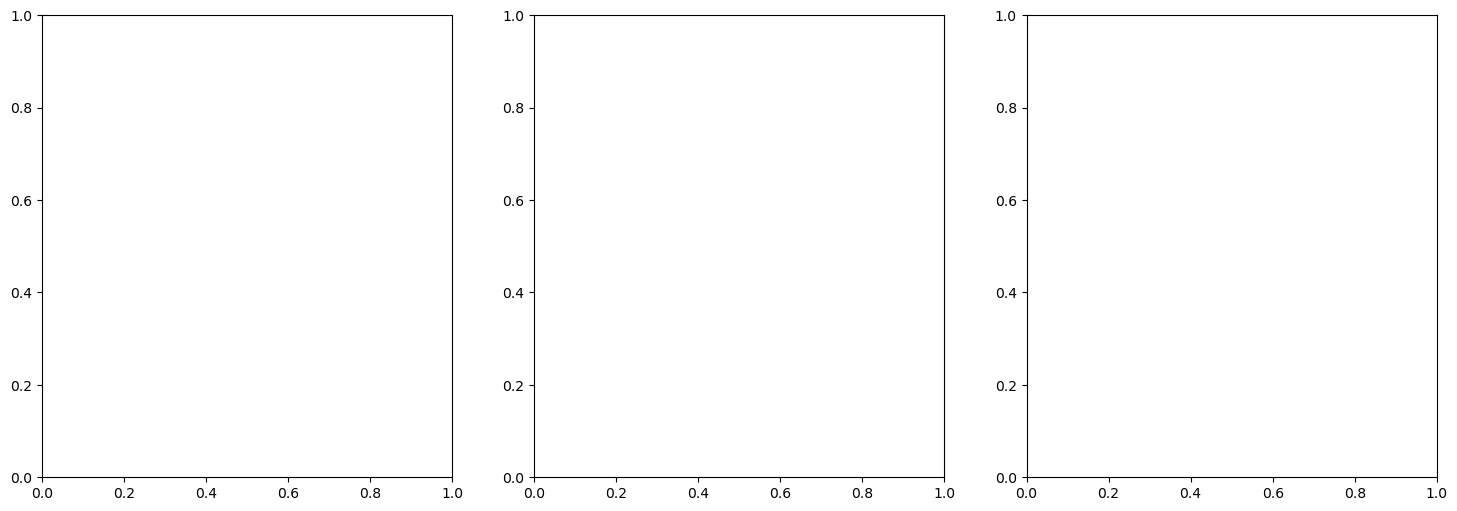

In [15]:
coefs = best_clf.coef_
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
titles = ["Top Fitur: Normal", "Top Fitur: Penipuan", "Top Fitur: Promosi"]
bar_colors = ['#15803d', '#b91c1c', '#b45309']

for i in range(3):
    top10_idx = np.argsort(coefs[i])[-10:]
    top_words = [feature_names[j] for j in top10_idx]
    top_weights = coefs[i][top10_idx]
    
    axes[i].barh(top_words, top_weights, color=bar_colors[i], edgecolor='#0f172a')
    axes[i].set_title(titles[i], fontsize=12, fontweight='bold')
    axes[i].set_xlabel("Bobot Koefisien (W)", fontsize=10)

plt.tight_layout()
plt.show()

## 12. Penyimpanan Model Terlatih (.joblib)
Menyimpan artefak model terbaik dan ekstraktor TF-IDF agar dapat dimuat instan pada antarmuka web Streamlit.

In [16]:
os.makedirs("models", exist_ok=True)

joblib.dump(best_clf, "models/best_model_id.joblib")
joblib.dump(vectorizer, "models/tfidf_vectorizer_id.joblib")

print("[OK] Model terbaik (Logistic Regression) tersimpan di : models/best_model_id.joblib")
print("[OK] Ekstraktor TF-IDF tersimpan di                 : models/tfidf_vectorizer_id.joblib")

[OK] Model terbaik (Logistic Regression) tersimpan di : models/best_model_id.joblib
[OK] Ekstraktor TF-IDF tersimpan di                 : models/tfidf_vectorizer_id.joblib


## 13. Pengujian Inferensi Interaktif pada Teks Baru
Fungsi inferensi siap pakai yang menerima teks mentah baru, menjalankan pra-pemrosesan, vektorisasi, dan mengeluarkan persentase probabilitas terkalibrasi.

In [17]:
def predict_sms(raw_text: str):
    cleaned = clean_text_id(raw_text)
    vec = vectorizer.transform([cleaned])
    pred_idx = best_clf.predict(vec)[0]
    probs = best_clf.predict_proba(vec)[0]
    
    labels = ["NORMAL", "PENIPUAN", "PROMOSI"]
    print(f"Teks Input   : {raw_text}")
    print(f"Teks Bersih  : {cleaned}")
    print(f"Hasil Prediksi: [{labels[pred_idx]}]")
    print(f"Keyakinan    : Normal: {probs[0]*100:.2f}% | Penipuan: {probs[1]*100:.2f}% | Promosi: {probs[2]*100:.2f}%")
    print("-" * 70)

# Uji coba 3 kasus nyata berbeda
print("=== UJI COBA INFERENSI MODEL ===\n")
predict_sms("Surat Keputusan Resmi Shopee: Anda terpilih pemenang Rp 175jt PIN: 254F77 Hub WA: 081298765432")
predict_sms("Paket Flash Spesial 25GB hanya Rp 50.000 aktifkan sekarang di *363*88# sebelum masa berlaku habis.")
predict_sms("Bro besok pagi kumpul di perpus jam 9 ya buat ngerjain tugas akhir bareng kelompok machine learning.")

=== UJI COBA INFERENSI MODEL ===

Teks Input   : Surat Keputusan Resmi Shopee: Anda terpilih pemenang Rp 175jt PIN: 254F77 Hub WA: 081298765432
Teks Bersih  : surat keputusan resmi shopee anda terpilih pemenang [nominal] juta pin 254f77 hubungi wa [nomor]
Hasil Prediksi: [PENIPUAN]
Keyakinan    : Normal: 1.88% | Penipuan: 96.07% | Promosi: 2.05%
----------------------------------------------------------------------
Teks Input   : Paket Flash Spesial 25GB hanya Rp 50.000 aktifkan sekarang di *363*88# sebelum masa berlaku habis.
Teks Bersih  : paket flash spesial 25gb hanya [nominal] aktifkan sekarang di [kode] sebelum masa berlaku habis
Hasil Prediksi: [PROMOSI]
Keyakinan    : Normal: 7.49% | Penipuan: 2.64% | Promosi: 89.87%
----------------------------------------------------------------------
Teks Input   : Bro besok pagi kumpul di perpus jam 9 ya buat ngerjain tugas akhir bareng kelompok machine learning.
Teks Bersih  : bro besok pagi kumpul di perpus jam 9 ya buat ngerjain tugas ak